## Занятие 7. Базовые графики (визуализация распределения)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style('whitegrid')
df = pd.read_csv('employee_data.csv')

### Задание 1. Гистограмма и KDE для зарплаты

In [2]:
df.head()

,EmployeeID,Age,Tenure,Salary,Department,Rating
0,E001,37,1,30000,Marketing,4
1,E002,43,1,30000,Marketing,5
2,E003,26,5,30000,Sales,4
3,E004,32,0,30000,Finance,4
4,E005,37,1,30000,Marketing,3


In [3]:
df[['Age', 'Tenure', 'Salary']].describe()

,Age,Tenure,Salary
count,200.000000,200.000000,200.000000
mean,37.355000,1.800000,34728.610000
std,7.850934,1.713089,28995.547171
min,22.000000,0.000000,30000.000000
25%,31.000000,0.000000,30000.000000
50%,37.000000,1.000000,30000.000000
75%,44.000000,3.000000,30000.000000
max,65.000000,7.000000,350000.000000


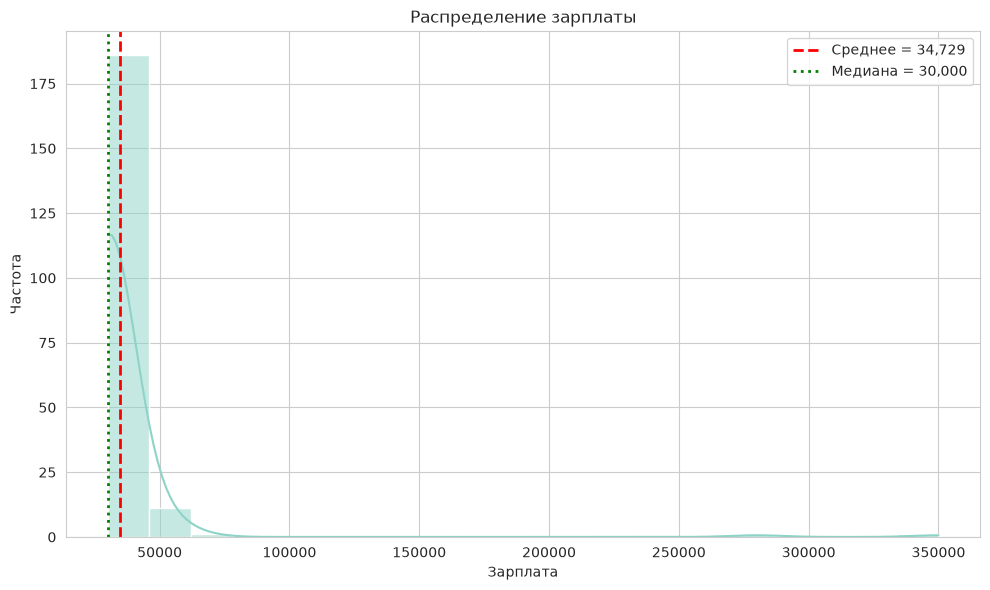

Среднее = 34,728.61
Медиана = 30,000.00
Skew = 9.610


In [4]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Salary'], bins=20, kde=True)

mean_salary = df['Salary'].mean()
median_salary = df['Salary'].median()
plt.axvline(mean_salary, color='red', linestyle='--', linewidth=2, label=f'Среднее = {mean_salary:,.0f}')
plt.axvline(median_salary, color='green', linestyle=':', linewidth=2, label=f'Медиана = {median_salary:,.0f}')

plt.title('Распределение зарплаты')
plt.xlabel('Зарплата')
plt.ylabel('Частота')
plt.legend()
plt.tight_layout()
plt.show()

print(f"Среднее = {mean_salary:,.2f}")
print(f"Медиана = {median_salary:,.2f}")
print(f"Skew = {df['Salary'].skew():.3f}")

**Вывод:** среднее (34 729) заметно выше медианы (30 000), skew = 9.6 — распределение зарплаты сильно скошено вправо из-за нескольких очень высоких зарплат (Sales до 350 000). Бимодальности нет, есть правый тяжёлый хвост.

### Задание 2. Ящики с усами по отделам

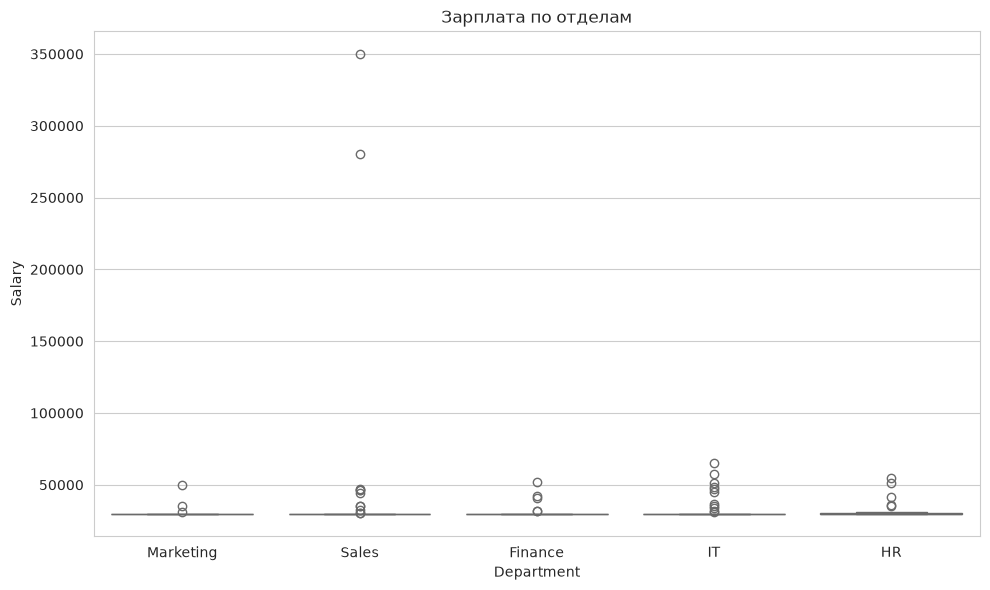

In [5]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Department', y='Salary', data=df)
plt.title('Зарплата по отделам')
plt.tight_layout()
plt.show()

In [6]:
median_by_dept = df.groupby('Department')['Salary'].median().sort_values(ascending=False)
spread_by_dept = df.groupby('Department')['Salary'].std().sort_values(ascending=False)

print('Медианная зарплата по отделам:')
print(median_by_dept)
print()
print('Ст. отклонение (разброс) по отделам:')
print(spread_by_dept)

Медианная зарплата по отделам:
Department
Finance      30000.0
HR           30000.0
IT           30000.0
Marketing    30000.0
Sales        30000.0
Name: Salary, dtype: float64

Ст. отклонение (разброс) по отделам:
Department
Sales        52338.426076
IT            7592.075099
HR            6252.923635
Marketing     4910.369756
Finance       4000.397706
Name: Salary, dtype: float64


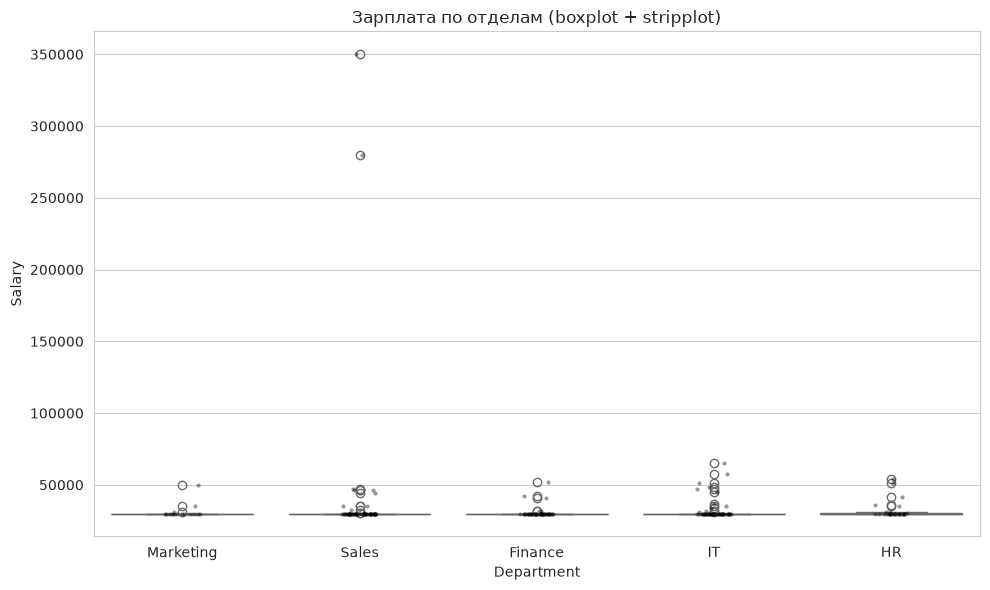

In [7]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Department', y='Salary', data=df)
sns.stripplot(x='Department', y='Salary', data=df, jitter=True, color='black', alpha=0.4, size=3)
plt.title('Зарплата по отделам (boxplot + stripplot)')
plt.tight_layout()
plt.show()

**Вывод:** медианные зарплаты во всех отделах одинаковые (30 000), но разброс сильно различается: в Sales огромный разброс (std ≈ 52 338) из-за нескольких экстремально высоких зарплат и выбросов; в остальных отделах разброс умеренный. Точки stripplot показывают, что почти все зарплаты лежат в узком диапазоне около 30 000, а выбросы — единичны.

### Задание 3. Сравнение распределений стажа и возраста

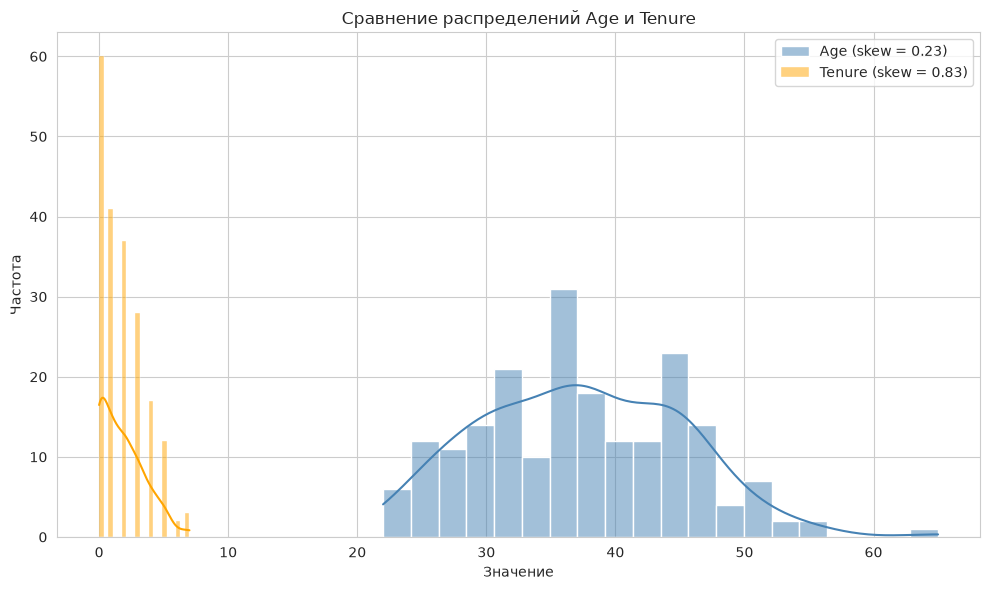

In [8]:
skew_age = df['Age'].skew()
skew_tenure = df['Tenure'].skew()

plt.figure(figsize=(10, 6))
sns.histplot(df['Age'], bins=20, kde=True, color='steelblue', alpha=0.5, label=f'Age (skew = {skew_age:.2f})')
sns.histplot(df['Tenure'], bins=20, kde=True, color='orange', alpha=0.5, label=f'Tenure (skew = {skew_tenure:.2f})')

plt.title('Сравнение распределений Age и Tenure')
plt.xlabel('Значение')
plt.ylabel('Частота')
plt.legend()
plt.tight_layout()
plt.show()

**Вывод:** оба признака скошены вправо, но Tenure (skew = 0.83) — сильнее, чем Age (skew = 0.23): у компании много новичков с маленьким стажем. Age ближе к симметричному.

### Задание 4. Violinplot по отделам для оценки эффективности

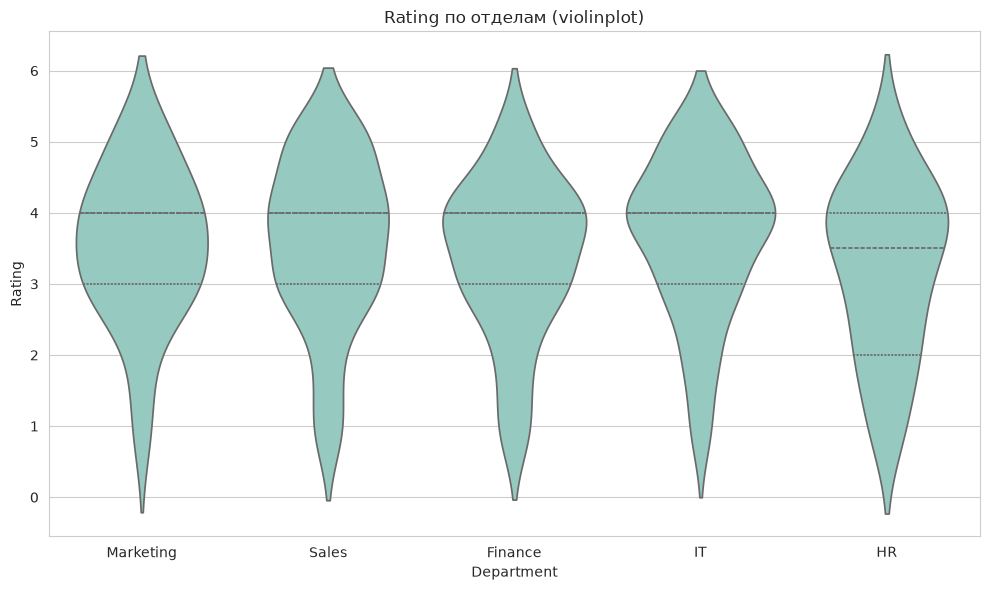

In [9]:
plt.figure(figsize=(10, 6))
sns.violinplot(x='Department', y='Rating', data=df, inner='quartile')
plt.title('Rating по отделам (violinplot)')
plt.tight_layout()
plt.show()

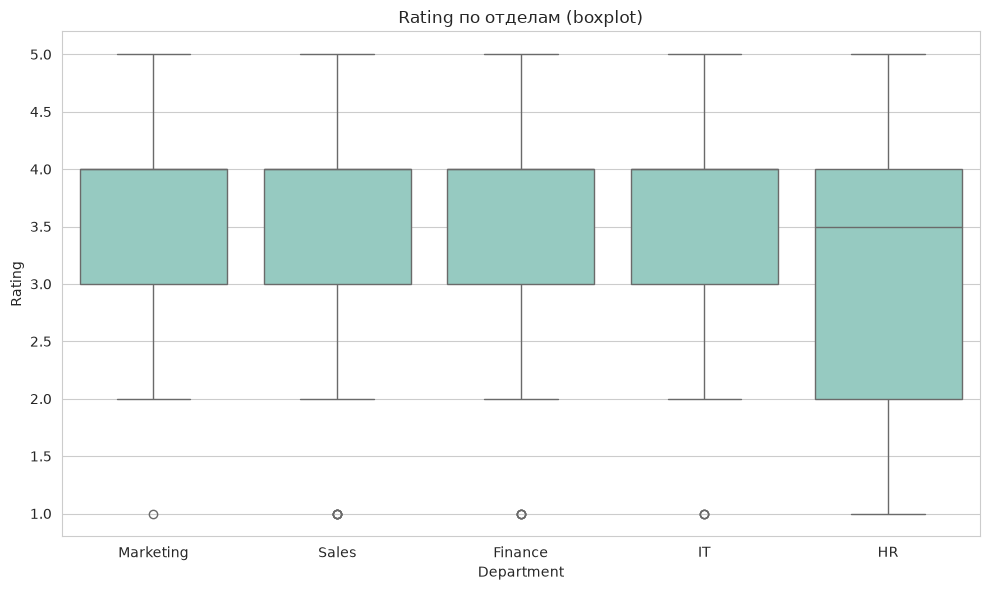

In [10]:
plt.figure(figsize=(10, 6))
sns.boxplot(x='Department', y='Rating', data=df)
plt.title('Rating по отделам (boxplot)')
plt.tight_layout()
plt.show()

In [11]:
rating_stats = df.groupby('Department')['Rating'].agg(['mean', 'median', 'min', 'max', 'count'])
print('Статистики Rating по отделам:')
print(rating_stats)
print()
print('Минимальные оценки (провалы) по отделам:')
print(df[df['Rating'] <= 2].groupby('Department')['Rating'].count())

Статистики Rating по отделам:
                mean  median  min  max  count
Department                                   
Finance     3.363636     4.0    1    5     44
HR          3.214286     3.5    1    5     28
IT          3.634615     4.0    1    5     52
Marketing   3.529412     4.0    1    5     17
Sales       3.559322     4.0    1    5     59

Минимальные оценки (провалы) по отделам:
Department
Finance      8
HR           8
IT           8
Marketing    2
Sales        9
Name: Rating, dtype: int64


**Вывод:** Rating — дискретная переменная (1-5), поэтому violinplot показывает «слои» вместо гладкой плотности; boxplot для дискретных данных информативнее. Средние оценки по отделам близки (3.2–3.6), наиболее низкие — в HR; «провалы» (оценки ≤ 2) есть во всех отделах, больше всего в Sales (9).

### Задание 5. Проверка нормальности (Q-Q plot)

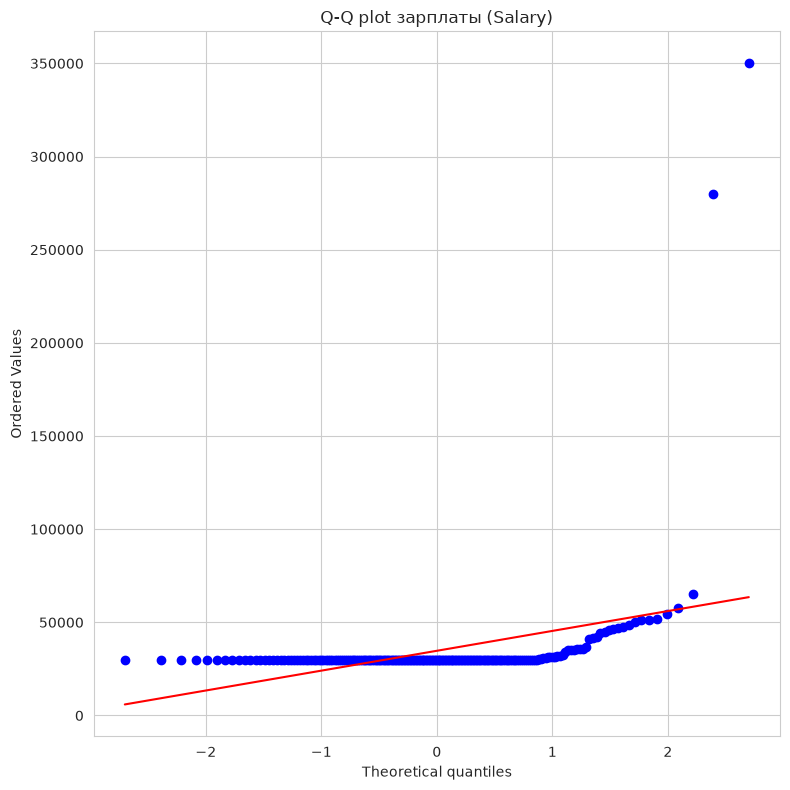

In [12]:
plt.figure(figsize=(8, 8))
stats.probplot(df['Salary'], dist='norm', plot=plt)
plt.title('Q-Q plot зарплаты (Salary)')
plt.tight_layout()
plt.show()

**Вывод:** точки в правой части заметно отклоняются вверх от прямой — правый тяжёлый хвост из-за нескольких экстремально высоких зарплат, распределение зарплаты отклоняется от нормального вправо. Это согласуется с Заданием 1: skew = 9.6, среднее сильно выше медианы.